### Opgaver i dataanalyse

#### Opgave 1 - Regressionsanalyse af lineær funktion

a) Foretag en lineær regression med modellen $x=A+Bt$ for data givet nedenfor.

b) Kan de fundne værdier for $A$ og $B$ være heltallige? JA

[1.99131165 3.01838674]
[0.06668488 0.04529595]
A = 1.99+/-0.07
B = 3.02+/-0.05
dv = 0.04983902483884575


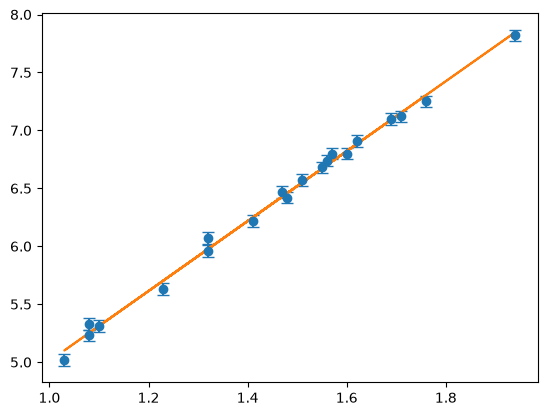

In [19]:
import numpy as np
t = np.array([1.56, 1.1, 1.55, 1.69, 1.48, 1.32, 1.32, 1.23, 1.51, 1.47, 1.41, 1.71, 1.94, 1.57, 1.62, 1.03, 1.08, 1.76, 1.6, 1.08])
x = np.array([6.74, 5.31, 6.68, 7.1, 6.42, 6.07, 5.96, 5.63, 6.57, 6.47, 6.22, 7.12, 7.82, 6.8, 6.91, 5.02, 5.23, 7.25, 6.8, 5.33])



import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import uncertainties as unc

y = x
x = t

N = len(y)

def f(x,A,B):
    return A+B*x
param,cov = curve_fit(f,x,y)
print(param)
print(np.sqrt(np.diag(cov)))

A = unc.ufloat(param[0],np.sqrt(np.diag(cov))[0])
B = unc.ufloat(param[1],np.sqrt(np.diag(cov))[1])

print('A = {}'.format(A))
print('B = {}'.format(B))

dv = np.std(y-f(x,*param),ddof=2)

print('dv = {}'.format(dv))
plt.figure()
plt.errorbar(x,y,yerr=dv,fmt='o',capsize=4)
plt.plot(x,f(x,*param))
plt.show()

#### Opgave 2 - Regressionanalyse af frit fald med støjfyldte målinger

En bold tabes fra højden $h=10$ m. 

a) Beregn tid og positionen, $t$ og $x$, i vektorer med 15 ækvidistante datapunkter under det frie fald indtil bolden rammer jorden.
Tilføj normalfordelt støj til positionerne med en middelværdi på nul og en standardafvigelse på 0.2. (Vink: *numpy.random.normal()*)
<details>
<summary>Få et vink - klik her</summary>
np.random.normal(loc=...,scale=...,size=np.size(t)
</details>

b) Foretag en regressionsanalyse af en passende model $x=f(t)$.
<details>
<summary>Få et vink - klik her</summary>
Du kan bruge en kinematisk formel, x=h-1/2gt^2, fx hvis din x-akse peger op ad.
</details>

c) Hvad er den bestemte værdi af tyngdeaccelerationen, $g$? Er den sammenlignelig med den accepterede værdi, $g=9.82 \text{m/s}^2$.
<details>
<summary>Få et vink - klik her</summary>
Har du husket at hvis Ct^2 er 2C=g?
</details>



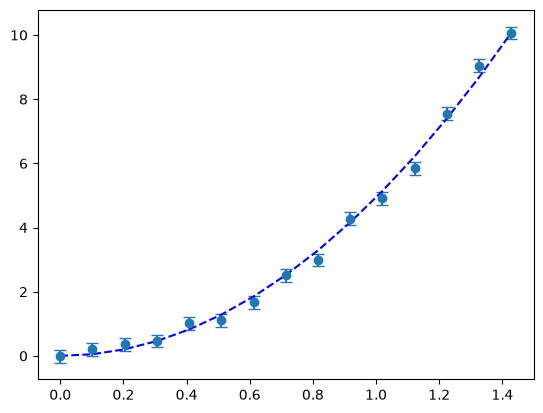

g = 9.87+/-0.11


In [30]:
import numpy as np
h = 10
g_true = 9.81

# OPG a)

t_fald = np.sqrt(2 * h / g_true)

t = np.linspace(0, t_fald, 15)

x_true = 1/2 * g_true * t**2

x = x_true + np.random.normal(0, 0.2, 15)

# OPG b)
from scipy.optimize import curve_fit
import uncertainties as unc
import matplotlib.pyplot as plt

def f(t,g):
    return 1/2 * g * t**2
param,cov = curve_fit(f,t,x)

dv = np.std(x-f(t,*param))
plt.figure()
plt.errorbar(t,x,yerr=dv,fmt='o',capsize=4)
plt.plot(t,f(t,*param),'b--')
plt.show()

# OPG c)
g = unc.ufloat(param[0],np.sqrt(np.diag(cov))[0])
print('g = {}'.format(g))

#### Opgave 3 - Fjederkonstanter


To fjedre er monteret med fælles centrum og akse. 
Den ene fjeder har fjederkonstant $k_1$ og denne er 40 cm længere end den anden fjeder der har fjederkonstant, $k_2$.
Når der skubbes med et legeme virker der en fjederkraft fra $k_1$ med det samme, $k_2$ leverer først en fjederkraft når 
deformationen er større end 40 cm.

Vektorerne *x* og *F* nedenfor indeholder måleværdier for deformation og samlet kraft.

a) Bestem fjederkonstanterne vha. to regressionsanalyser.

<details>
<summary>Få et vink - klik her</summary>
Hvis du vil fx udtage de første tre elementer i en vektor kan du skrive x[0:3],
der vil returnere en vektor [x[0],x[1],x[2]], bemærk at den ikke indholder x[3].
Hvis du vil udtage de sidste fire elementer kan du skrive x[-4:].
</details>

In [ ]:
import numpy as np
x = np.array([0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0])
F = np.array([70,135,205,281,609,889,1202,1512,1785,2011])

k1 = F[:4]/x[:4]


#### Opgave 4 - Svingningstid for pendul

Vi undersøger et penduls svingningstid, $T$, som funktion af amplituden af udsvinget, $\theta$.
Vi har data liggende i vektorerne *T* og *theta* og der er et plot af sammenhængen.

a) Foreslå en regressionsmodel, $T=f(\theta)$ og udfør en dataanalyse. Gentag indtil du har en tilfredsstillende model.

In [18]:
# NEDENSTÅENDE ER IKKE EN DEL AF LØSNINGEN, DET ER DATAGENERERING
import numpy as np
from scipy.integrate import solve_ivp
g = 9.82
l = 0.25
def f(t,x):
    theta,omega = x
    return [omega,-g/l*np.sin(theta)]
def zero(t,z):
    theta,omega = z
    return omega
zero.direction = 1 
zero.terminal = True
vinkel = []
T = []
for grader in np.linspace(1,30,20):
    theta = grader * np.pi / 180.0
    sol = solve_ivp(f,t_span=[0,10],y0=[theta,0],events=[zero],atol=1e-8,rtol=1e-8) 
    T.append(sol.t_events[0][0])
    vinkel.append(theta)

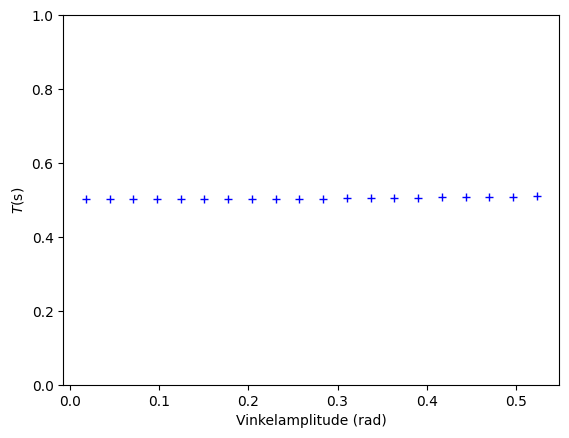

In [19]:
import matplotlib.pyplot as plt
plt.figure()
plt.ylim(0,1)
plt.xlabel('Vinkelamplitude (rad)')
plt.ylabel('$T$(s)')
plt.plot(vinkel,T,'b+')
plt.show()

#### Opgave 5 - Opstil model og regressionsanalyse

Vi har givet data med y-usikkerheder (sidstnævnte beregnes).

a) Foreslå en model og foretag en regressionsanalyse af data.

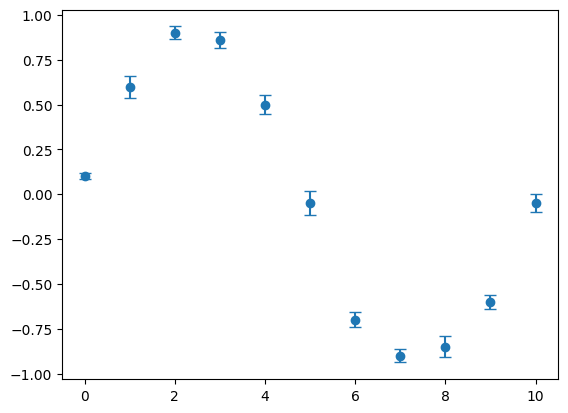

In [23]:
import numpy as np
x = np.array([0,1,2,3,4,5,6,7,8,9,10])
y = np.array([0.1,0.6,0.9,0.86,0.5,-0.05,-0.7,-0.9,-0.85,-0.6,-0.05])
dy = np.random.normal(loc=0.05,scale=0.02,size = np.size(x))
import matplotlib.pyplot as plt
plt.figure()
plt.errorbar(x,y,yerr=dy,fmt='o',capsize=4)
plt.show()